# Tree SHAP explanations and RQ2

This notebook displays the committed SHAP analysis from `10_XGBoost_SHAP.py`. It includes a fixed 4,000-record sample of held-out hospitals D-G. Set `RUN_SHAP=True` to regenerate explanations from the saved model.

In [1]:
from pathlib import Path
import base64
import subprocess
import sys
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
TABLES = ROOT / 'reports/tables'
def show_image(name):
    display(Image(filename=str(ROOT / 'reports/figures' / name)))
print('Repository', ROOT.name)


Repository LeukoGuard_Project


## Reproduce Tree SHAP

TreeExplainer uses tree-path-dependent attribution in raw log-odds. Positive SHAP values raise the leukemia-class score relative to the baseline and negative values lower it. The script checks that the logistic transform of the baseline plus contributions reconstructs the model score.

In [2]:
RUN_SHAP = False
if RUN_SHAP:
    subprocess.run([sys.executable, str(ROOT / 'notebooks/10_XGBoost_SHAP.py')], cwd=ROOT, check=True)
print('Reviewing saved SHAP outputs' if not RUN_SHAP else 'SHAP completed')
sample = pd.read_csv(TABLES / 'XGB_shap_sample.csv')
display(sample.groupby('site').y.agg(['size', 'sum']).reset_index())

site,size,sum
D,809,36
E,2534,83
F,526,22
G,131,18


Reviewing saved SHAP outputs


## Global feature importance and direction

The beeswarm shows signed contributions and observed feature values. Mean absolute SHAP measures contribution magnitude. The CBC bar chart combines each measurement with its missingness indicator before computing magnitude. Quartile and decile profiles summarize observed associations and can conceal interactions.

feature,mean_abs_shap,mean_shap,positive_fraction,negative_fraction
PLT,0.750104,-0.588275,0.12300,0.87700
MicroR,0.388111,-0.261538,0.38650,0.61350
RDW-CV,0.378916,-0.166970,0.42475,0.57525
LY-X,0.365232,-0.296657,0.13425,0.86575
NEUT%&,0.357567,-0.151502,0.35625,0.64375
RBC,0.315742,-0.211887,0.25325,0.74675
NE-WX,0.285602,-0.193355,0.08650,0.91350
Fragments,0.270665,-0.148842,0.19175,0.80825
LY-WZ,0.268211,0.136544,0.69675,0.30325
LY-WX,0.258007,-0.094935,0.36425,0.63575


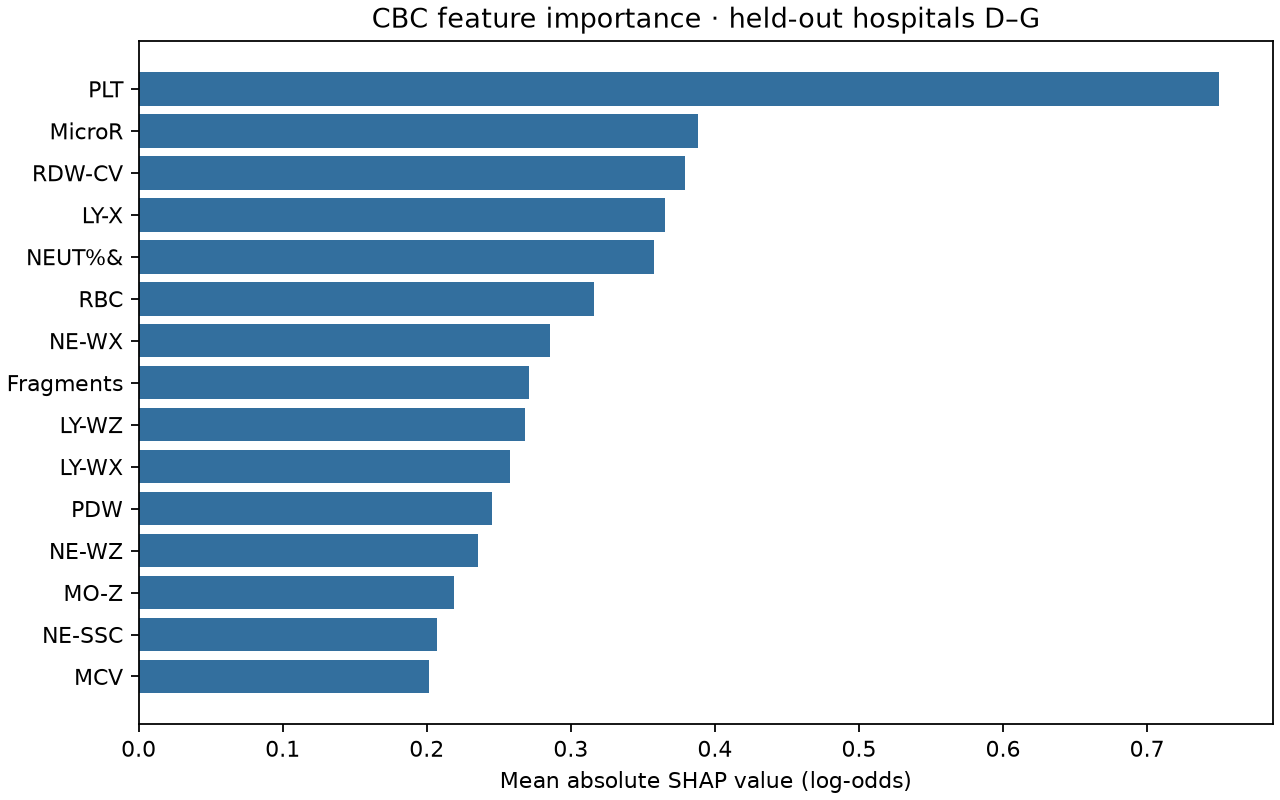

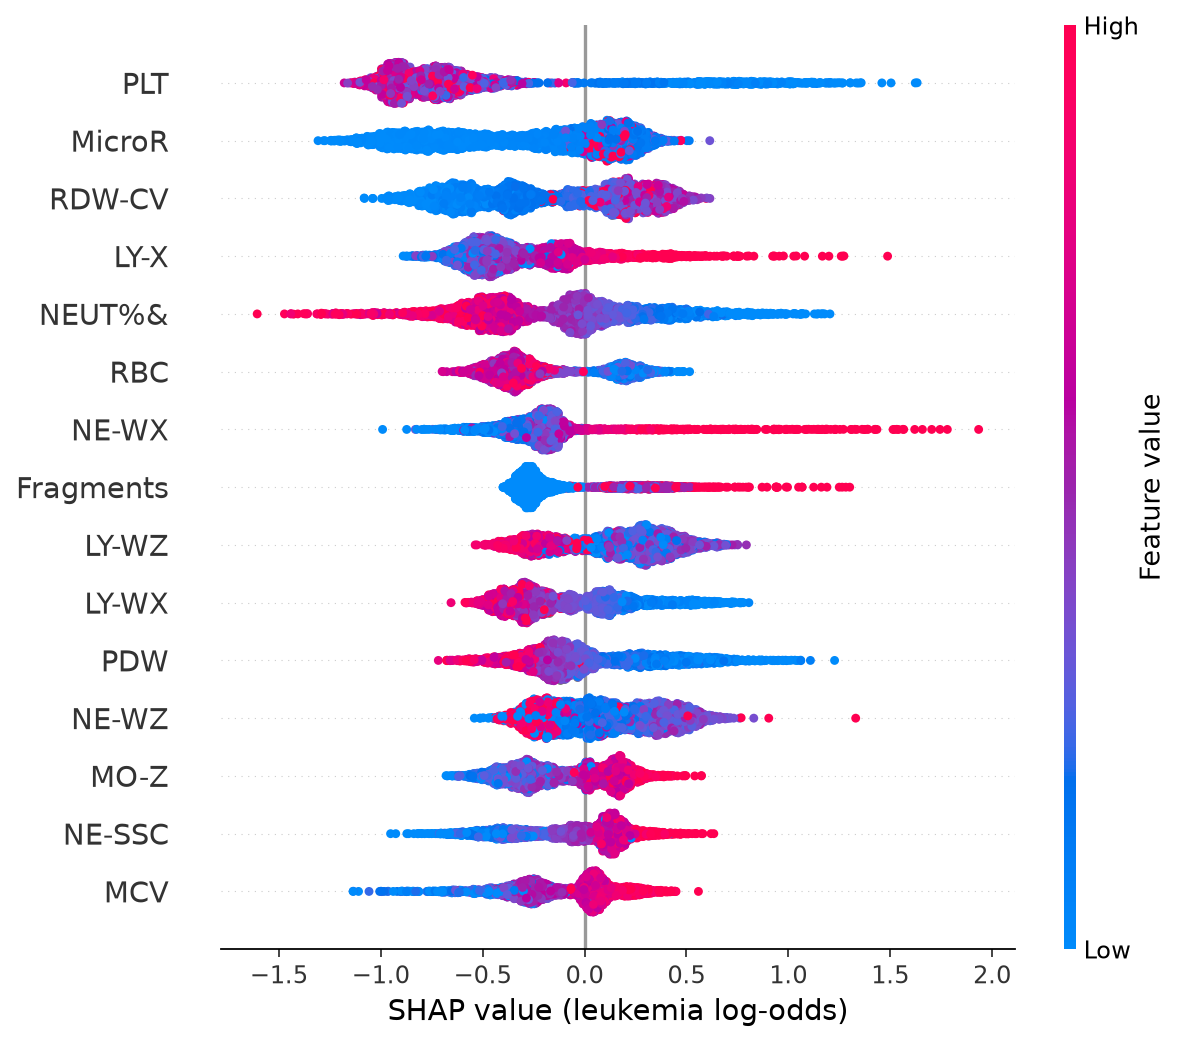

feature,mean_abs_shap,observed_n,missing_n,q25,q75,low_n,high_n,low_mean_shap,high_mean_shap,observed_positive_fraction,observed_negative_fraction
PLT,0.750103,4000,0,160.00,276.00,1002,1002,0.017445,-0.775637,0.123000,0.877000
MicroR,0.388111,4000,0,0.70,2.50,1128,1016,-0.821840,0.161747,0.386500,0.613500
RDW-CV,0.378916,3988,12,12.60,15.10,1038,1029,-0.669434,0.286330,0.423019,0.576981
LY-X,0.365232,3953,47,75.20,78.70,1021,989,-0.502346,0.093807,0.135846,0.864154
NEUT%&,0.357568,3937,63,55.80,75.70,987,990,0.385321,-0.608509,0.349759,0.650241
RBC,0.315742,4000,0,3.35,4.59,1009,1003,0.204420,-0.335477,0.253250,0.746750
NE-WX,0.285602,3952,48,298.00,323.00,990,1004,-0.402322,0.068866,0.087551,0.912449
Fragments,0.270665,3989,11,0.00,0.00,0,0,NaN,NaN,0.192279,0.807721
LY-WZ,0.268211,3953,47,452.00,573.00,996,994,0.202660,-0.217677,0.705034,0.294966
LY-WX,0.258007,3953,47,487.00,571.00,995,997,0.294463,-0.359310,0.368581,0.631419


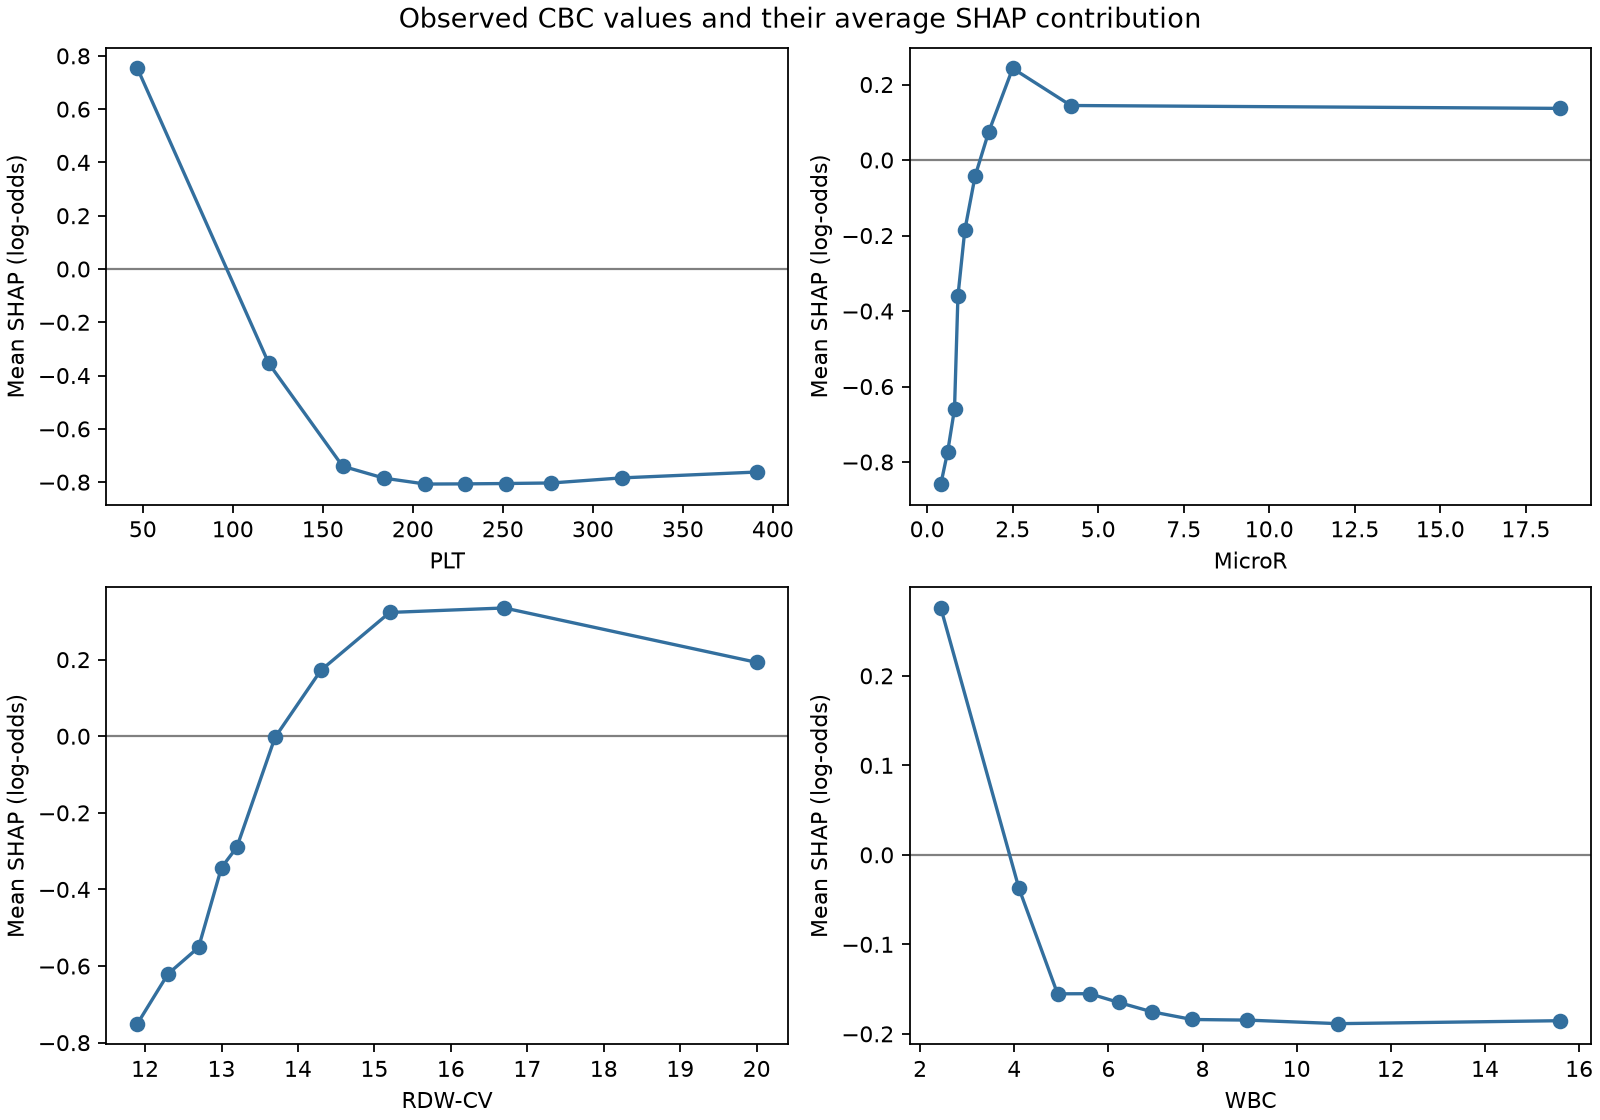

In [3]:
display(pd.read_csv(TABLES / 'XGB_shap_global.csv').head(15))
show_image('XGB_shap_global.png')
show_image('XGB_shap_beeswarm.png')
display(pd.read_csv(TABLES / 'XGB_shap_direction.csv').head(10))
show_image('XGB_shap_direction.png')

## Individual explanations

Cases were selected near the median score within true-positive, true-negative, false-positive and false-negative categories. The waterfalls show competing effects. A correctly reconstructed score can still produce a wrong classification. Verify the signed contributions for all four examples below.

case,sample_id,site,y,p,threshold,base_log_odds,model_log_odds
TP,patient_298302,E,1,0.982803,0.75385,0.016818,4.045657
TN,patient_289309,E,0,0.010893,0.75385,0.016818,-4.508696
FP,patient_356723,E,0,0.919146,0.75385,0.016818,2.430804
FN,patient_364958,F,1,0.407302,0.75385,0.016818,-0.375130


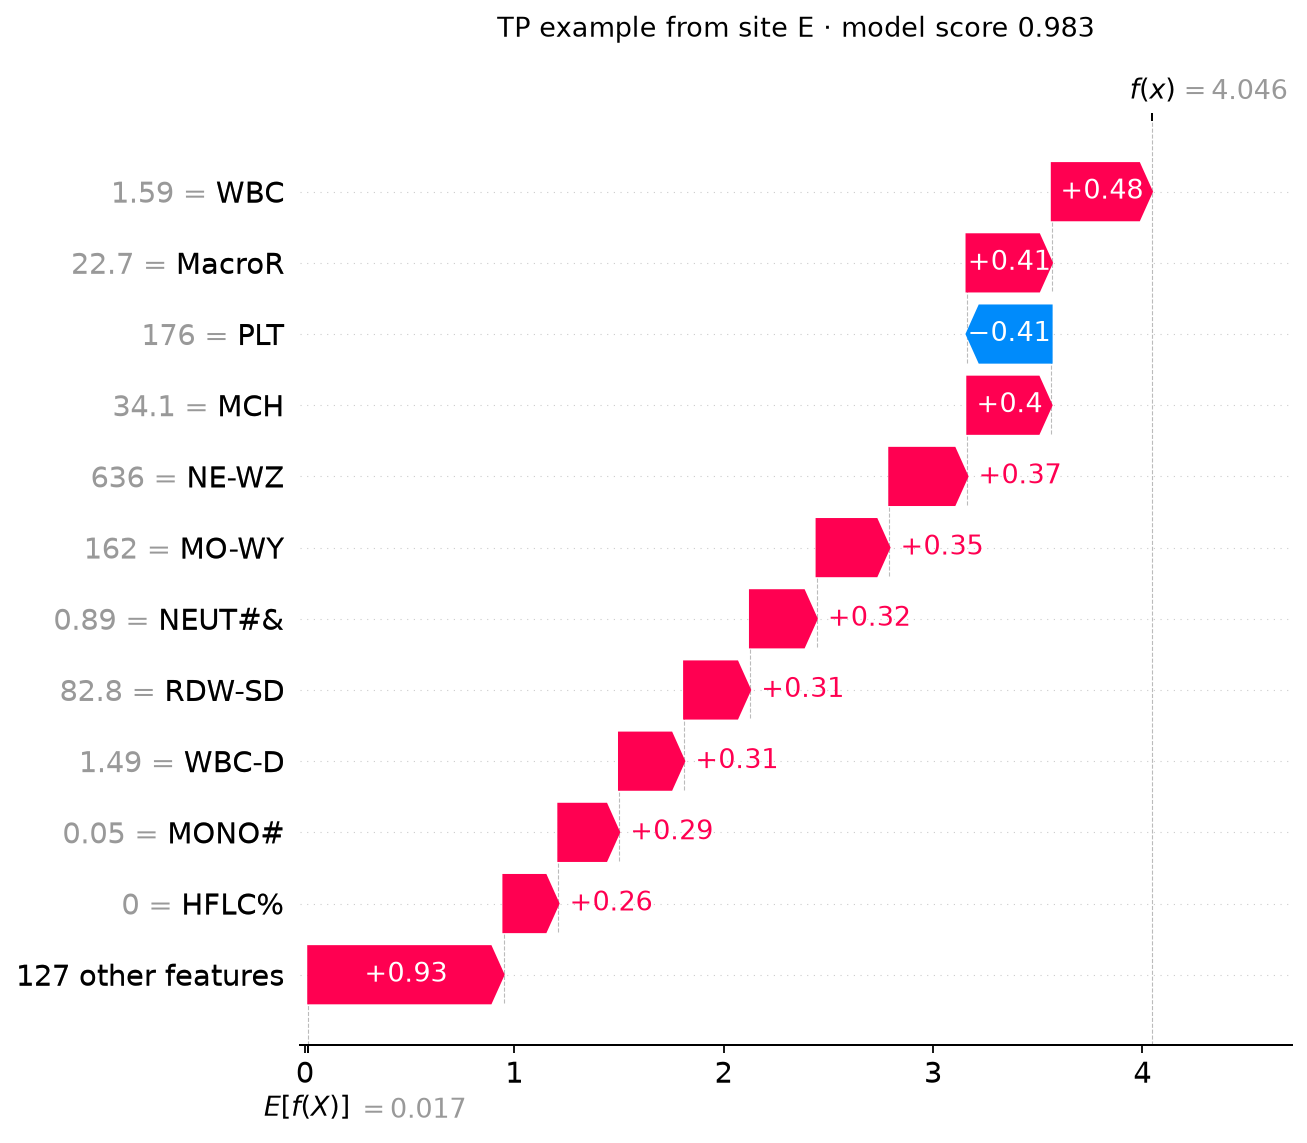

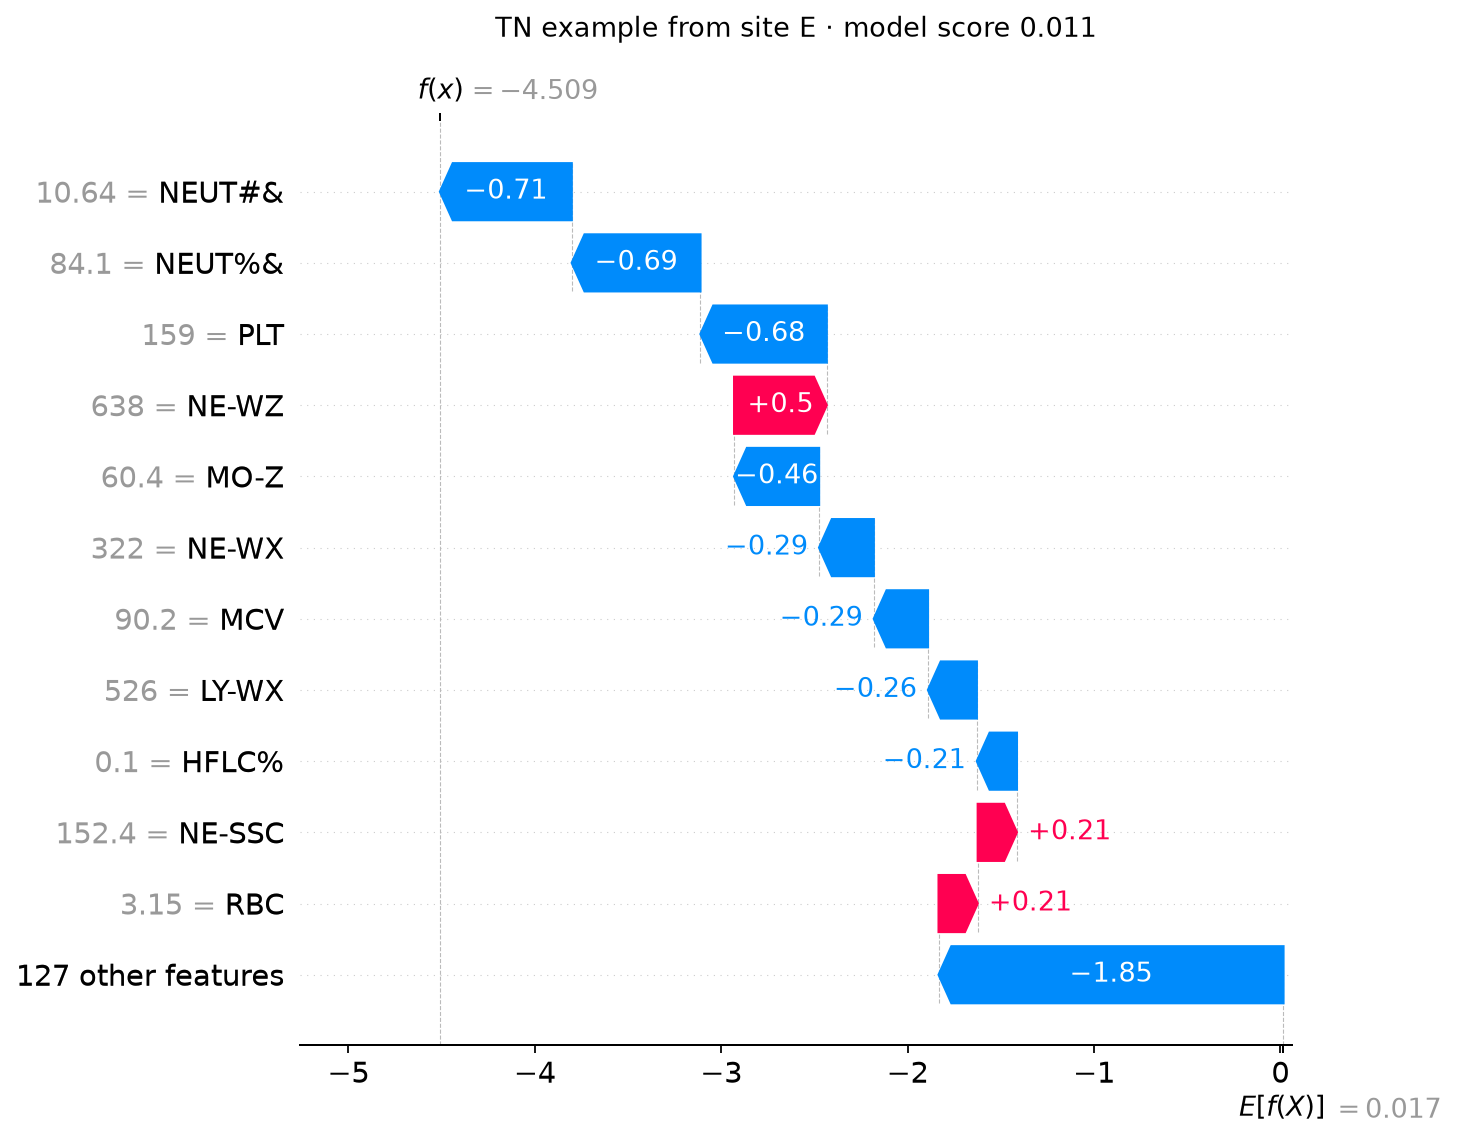

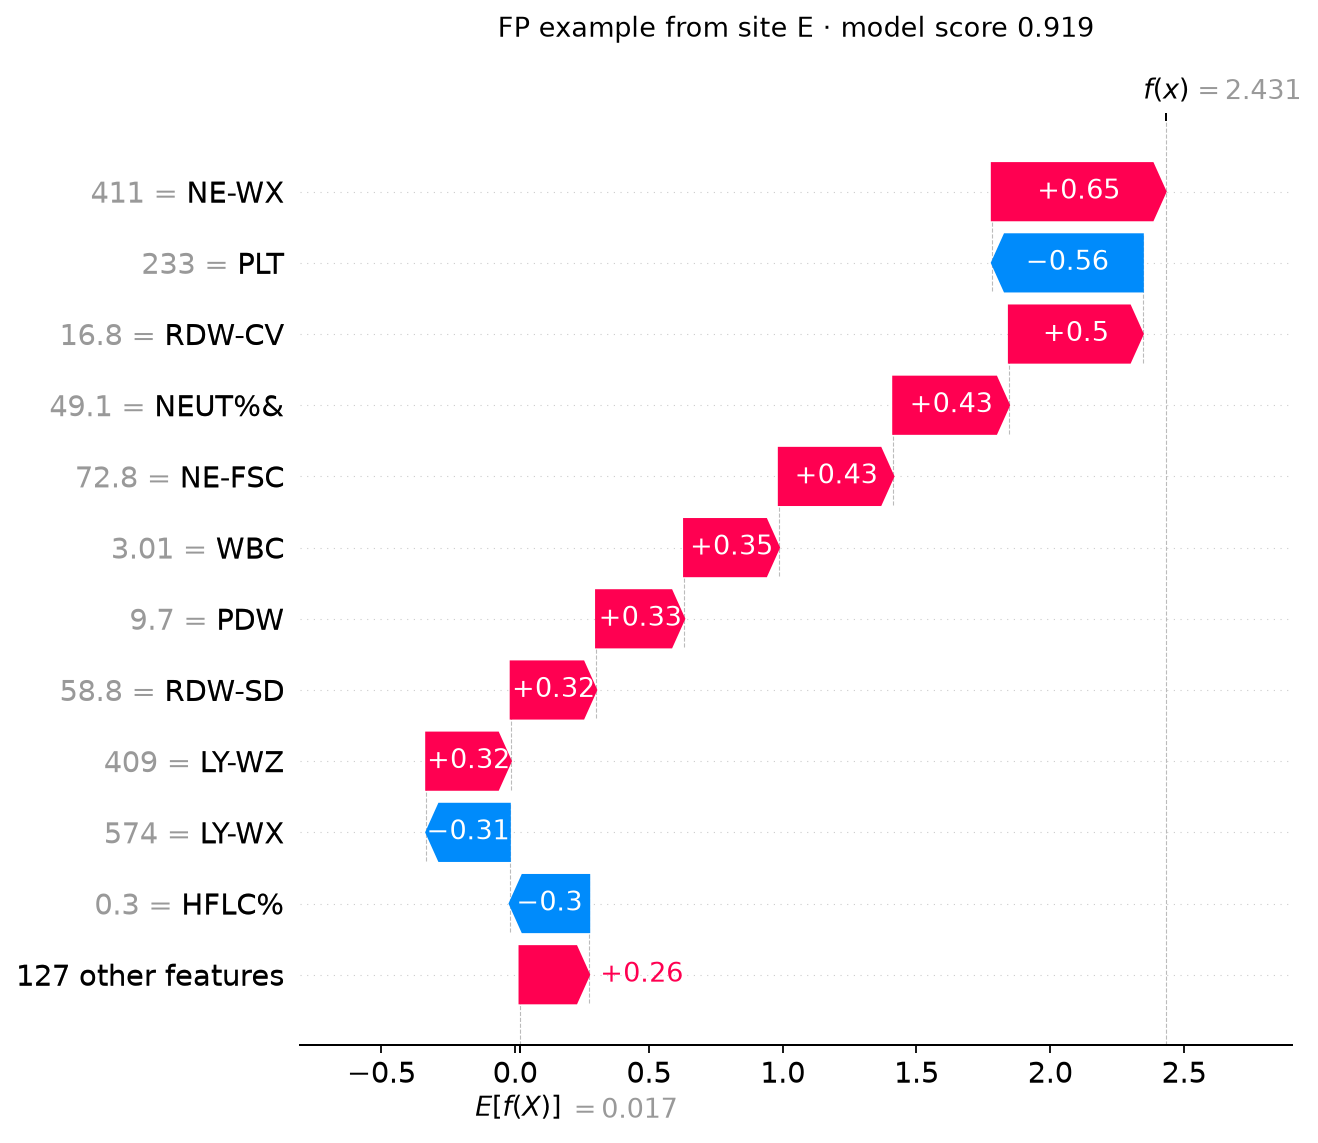

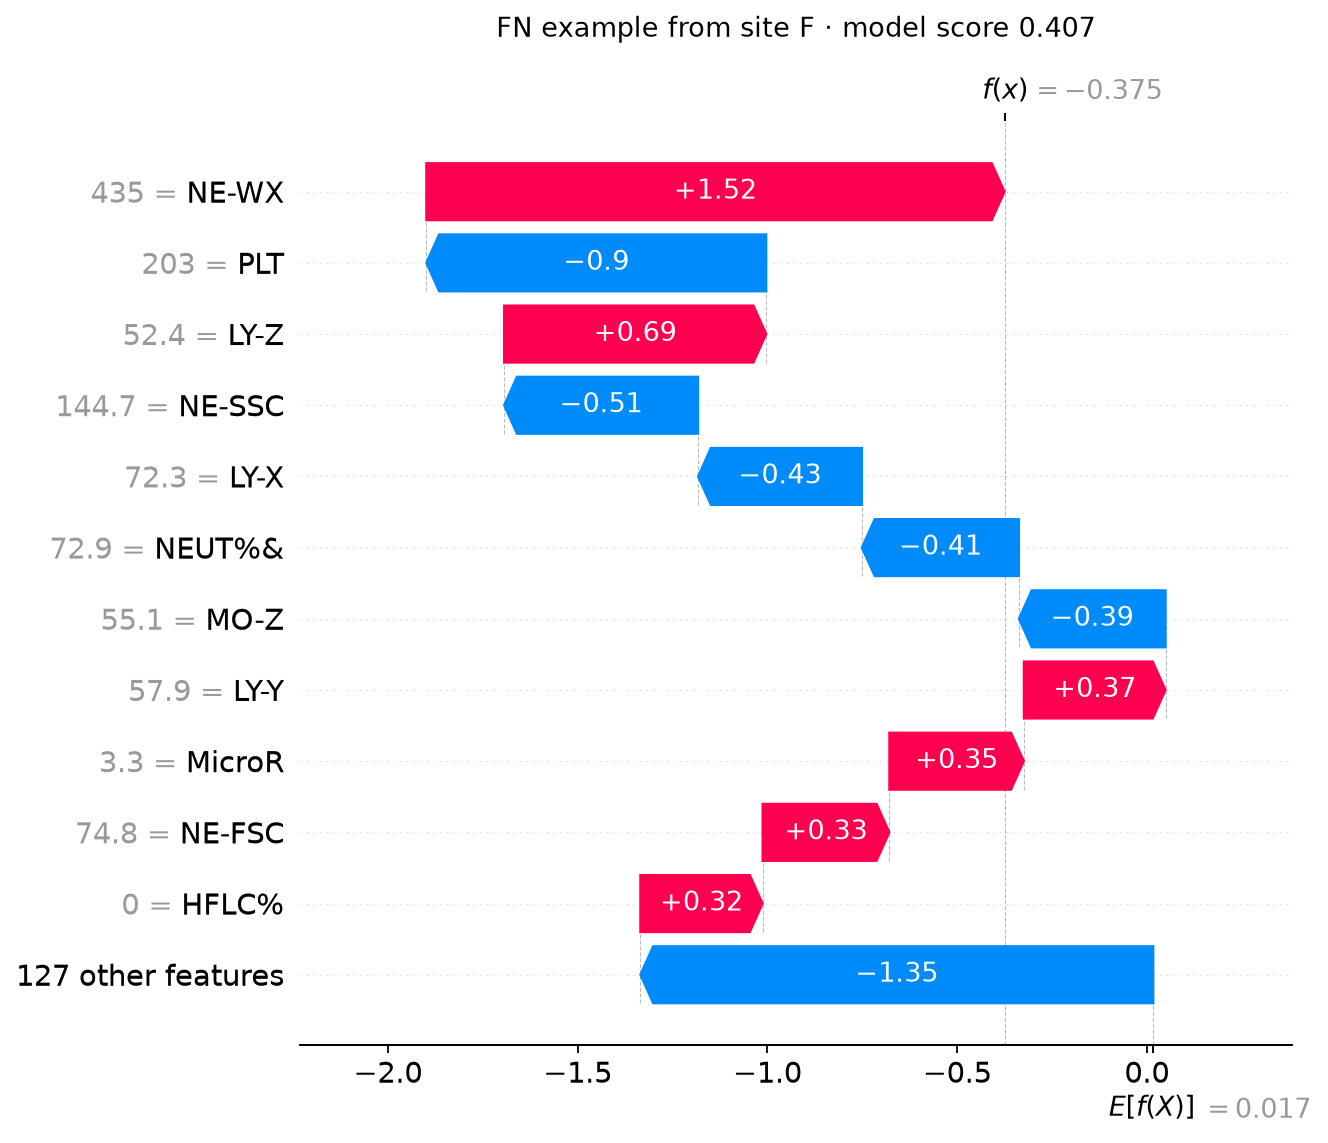

All four signed explanations reconstruct their model scores


In [4]:
import numpy as np
from scipy.special import expit
examples = pd.read_csv(TABLES / 'XGB_shap_examples.csv')
contributions = pd.read_csv(TABLES / 'XGB_shap_example_contributions.csv')
display(examples)
for case in ['TP', 'TN', 'FP', 'FN']:
    local = contributions[contributions.case.eq(case)]
    metadata = examples[examples.case.eq(case)].iloc[0]
    assert (local.shap_log_odds > 0).any() and (local.shap_log_odds < 0).any()
    np.testing.assert_allclose(expit(metadata.base_log_odds + local.shap_log_odds.sum()), metadata.p, atol=2e-5)
    show_image('XGB_shap_waterfall_' + case + '.png')
print('All four signed explanations reconstruct their model scores')

## Feature stability across models

All five fold models and the final model explain the same D-G records. Rankings combine each CBC measurement and its missingness indicator. Top-ten frequency, rank variability, pairwise Spearman correlation and Jaccard overlap quantify consistency. The fold training sets overlap, so this assesses sensitivity to the training fold.

In [5]:
stability = pd.read_csv(TABLES / 'XGB_shap_stability.csv')
display(stability[['feature', 'final_rank', 'fold_top10_count', 'mean_fold_rank', 'fold_rank_sd']].head(15))
display(pd.read_csv(TABLES / 'XGB_shap_stability_pairs.csv'))
print('Stable top-ten features:', ', '.join(stability.loc[stability.fold_top10_count.eq(5), 'feature']))

feature,final_rank,fold_top10_count,mean_fold_rank,fold_rank_sd
PLT,1,5,1.0,0.000000
RDW-CV,3,5,2.2,0.447214
MicroR,2,5,3.4,1.516575
LY-X,4,5,4.2,1.095445
NEUT%&,5,5,5.2,1.303840
RBC,6,5,6.6,2.073644
NE-WX,7,5,7.0,1.581139
LY-WZ,9,5,8.4,1.341641
Fragments,8,5,8.8,0.836660
LY-WX,10,3,9.0,2.549510


model_a,model_b,top10_overlap,top10_jaccard,rank_spearman
final,fold_0,10,1.000000,0.958484
final,fold_1,10,1.000000,0.964353
final,fold_2,10,1.000000,0.976224
final,fold_3,9,0.818182,0.970758
final,fold_4,9,0.818182,0.961670
fold_0,fold_1,10,1.000000,0.936553
fold_0,fold_2,10,1.000000,0.934977
fold_0,fold_3,9,0.818182,0.947150
fold_0,fold_4,9,0.818182,0.917471
fold_1,fold_2,10,1.000000,0.960731


Stable top-ten features: PLT, RDW-CV, MicroR, LY-X, NEUT%&, RBC, NE-WX, LY-WZ, Fragments


## RQ2 discussion

PLT ranks first in every fold. Very low PLT generally raises the model score, while higher PLT lowers it. Nine measurements occur in the top ten of every fold model. Correlated CBC measurements may share attribution, and several leading inputs are analyser-specific. These explanations describe the fitted model. Testing stability by hospital and on other analysers would strengthen the generalization analysis. The detailed discussion is in `docs/member3_results_summary.md`.